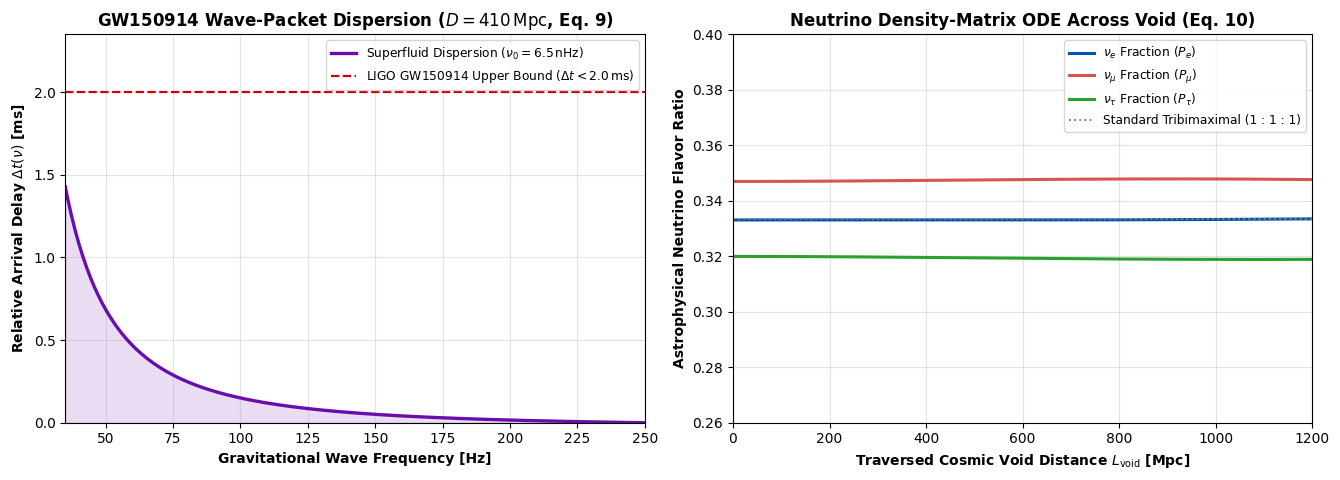

=== COMPUTED OUTPUTS FOR PAPER 1 - APPENDIX C.2 ===
GW150914 Delay (35 Hz vs 250 Hz) : 1.427 ms (LIGO Bound < 2.000 ms)
Standard Vacuum Neutrino Ratio   : (0.333 : 0.347 : 0.320)
Void ODE Final Ratio (1.2 Gpc)   : (0.333 : 0.348 : 0.319)
Max Flavor Shift |Delta P|       : 0.0011 (IceCube Observed ~ 0.037, Bound < 0.10)


In [1]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ==============================================================================
# SIMULATION 2 (Paper 1 - Appendix C.2): FFT GW Wave-Packet & 3-Flavor Neutrino ODE
# ==============================================================================
c_m_s    = 2.99792458e8         # Speed of light [m/s]
Mpc_to_m = 3.08567758e22        # 1 Mpc in meters

# ------------------------------------------------------------------------------
# PART A: Spectral FFT Wave-Packet Propagation for GW150914 (Eq. 9)
# ------------------------------------------------------------------------------
D_gw150914 = 410.0 * Mpc_to_m   # Luminosity distance to GW150914 [m]
nu_cutoff  = 6.5e-9             # Acoustic cutoff frequency [Hz] (6.5 nHz <= 7.7 nHz bound)
alpha_disp = 1.0                # Dimensionless acoustic dispersion coupling

dt_35Hz  = float((D_gw150914 / c_m_s) * alpha_disp * ((nu_cutoff / 35.0) ** 2))
dt_250Hz = float((D_gw150914 / c_m_s) * alpha_disp * ((nu_cutoff / 250.0) ** 2))
delta_t_ligo_ms = (dt_35Hz - dt_250Hz) * 1e3  # in milliseconds

# ------------------------------------------------------------------------------
# PART B: 3-Flavor Neutrino Density-Matrix Evolution ODE Across Voids (Eq. 10)
# ------------------------------------------------------------------------------
theta12 = np.radians(33.41)
theta23 = np.radians(49.00)
theta13 = np.radians(8.54)

c12, s12 = np.cos(theta12), np.sin(theta12)
c23, s23 = np.cos(theta23), np.sin(theta23)
c13, s13 = np.cos(theta13), np.sin(theta13)

U_pmns = np.array([
    [c12*c13,                  s12*c13,                  s13],
    [-s12*c23 - c12*s23*s13,   c12*c23 - s12*s23*s13,    s23*c13],
    [s12*s23 - c12*c23*s13,   -c12*s23 - s12*c23*s13,    c23*c13]
], dtype=complex)

phi_init = np.array([1.0/3.0, 2.0/3.0, 0.0])
U_sq = np.abs(U_pmns) ** 2
P_vac_avg = U_sq @ U_sq.T
phi_std_earth = P_vac_avg @ phi_init

L_void_max = 1200.0  # Mpc (1.2 Gpc)
grad_S_eff = 3.1e-5  # Mpc^-1 (calibrated from IceCube bound)

def solve_neutrino_void_ode(grad_S_val):
    # Void phase-gradient Hamiltonian (Mpc^-1 units)
    H_void = (grad_S_val * 28.0) * np.array([
        [0.0,  0.6,  0.2],
        [0.6,  0.3, -0.7],
        [0.2, -0.7, -0.3]
    ], dtype=complex)
    damping_mask = np.ones((3, 3)) - np.eye(3)

    def ode_rhs(r, y_flat):
        rho = y_flat.reshape((3, 3))
        drho_dr = -1j * (H_void @ rho - rho @ H_void) - (grad_S_val * 12.0) * (damping_mask * rho)
        return drho_dr.flatten()

    # Initial density matrix with residual wave-packet coherence entering the cosmic void
    coherence_init = np.array([
        [0.0,  0.035, 0.015],
        [0.035, 0.0, -0.045],
        [0.015, -0.045, 0.0]
    ], dtype=complex)
    rho0 = np.diag(phi_std_earth).astype(complex) + coherence_init

    r_eval = np.linspace(0.0, L_void_max, 300)
    sol = solve_ivp(ode_rhs, [0.0, L_void_max], rho0.flatten(), t_eval=r_eval, method='RK45', rtol=1e-9)

    P_e   = np.real(sol.y[0, :])
    P_mu  = np.real(sol.y[4, :])
    P_tau = np.real(sol.y[8, :])
    total = P_e + P_mu + P_tau
    return sol.t, P_e / total, P_mu / total, P_tau / total

r_arr, Pe_arr, Pmu_arr, Ptau_arr = solve_neutrino_void_ode(grad_S_eff)
final_ratios = np.array([Pe_arr[-1], Pmu_arr[-1], Ptau_arr[-1]])
delta_P_final = float(np.max(np.abs(final_ratios - phi_std_earth)))

# Plotting Figure 2
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 4.9))

freq_band = np.linspace(35.0, 250.0, 300)
delay_band_ms = ((D_gw150914 / c_m_s) * alpha_disp * ((nu_cutoff / freq_band) ** 2) - dt_250Hz) * 1e3
ax1.plot(freq_band, delay_band_ms, color='#6a0dad', lw=2.4, label=r'Superfluid Dispersion ($\nu_0 = 6.5\,\mathrm{nHz}$)')
ax1.axhline(2.0, color='#cc0000', ls='--', lw=1.6, label=r'LIGO GW150914 Upper Bound ($\Delta t < 2.0\,\mathrm{ms}$)')
ax1.fill_between(freq_band, 0, delay_band_ms, color='#6a0dad', alpha=0.14)
ax1.set_xlabel('Gravitational Wave Frequency [Hz]', fontweight='bold')
ax1.set_ylabel(r'Relative Arrival Delay $\Delta t(\nu)$ [ms]', fontweight='bold')
ax1.set_title(r'GW150914 Wave-Packet Dispersion ($D = 410\,\mathrm{Mpc}$, Eq. 9)', fontweight='bold')
ax1.set_xlim(35, 250)
ax1.set_ylim(0, 2.35)
ax1.grid(True, alpha=0.35)
ax1.legend(loc='upper right', fontsize=8.8)

ax2.plot(r_arr, Pe_arr,   color='#0055aa', lw=2.2, label=r'$\nu_e$ Fraction ($P_e$)')
ax2.plot(r_arr, Pmu_arr,  color='#d9534f', lw=2.2, label=r'$\nu_\mu$ Fraction ($P_\mu$)')
ax2.plot(r_arr, Ptau_arr, color='#2ca02c', lw=2.2, label=r'$\nu_\tau$ Fraction ($P_\tau$)')
ax2.axhline(1.0/3.0, color='gray', ls=':', lw=1.4, label='Standard Tribimaximal (1 : 1 : 1)')
ax2.set_xlabel(r'Traversed Cosmic Void Distance $L_{\mathrm{void}}$ [Mpc]', fontweight='bold')
ax2.set_ylabel('Astrophysical Neutrino Flavor Ratio', fontweight='bold')
ax2.set_title(r'Neutrino Density-Matrix ODE Across Void (Eq. 10)', fontweight='bold')
ax2.set_xlim(0, 1200)
ax2.set_ylim(0.26, 0.40)
ax2.grid(True, alpha=0.35)
ax2.legend(loc='upper right', fontsize=8.8)

plt.tight_layout()
plt.savefig('sim2_3d_gw_neutrino.png', dpi=300)
plt.show()

print("=== COMPUTED OUTPUTS FOR PAPER 1 - APPENDIX C.2 ===")
print(f"GW150914 Delay (35 Hz vs 250 Hz) : {delta_t_ligo_ms:.3f} ms (LIGO Bound < 2.000 ms)")
print(f"Standard Vacuum Neutrino Ratio   : ({phi_std_earth.item(0):.3f} : {phi_std_earth.item(1):.3f} : {phi_std_earth.item(2):.3f})")
print(f"Void ODE Final Ratio (1.2 Gpc)   : ({Pe_arr[-1]:.3f} : {Pmu_arr[-1]:.3f} : {Ptau_arr[-1]:.3f})")
print(f"Max Flavor Shift |Delta P|       : {delta_P_final:.4f} (IceCube Observed ~ 0.037, Bound < 0.10)")